# 1. Problem — a spatial and angular fluorescence inverse


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`observations`，shape `(1, 77, 55, 80, 21, 2)`，dtype `<u2`：Real registered camera counts, in digital counts; batch,X,Y,Z,state,view.；`lake_calibration`，shape `(1, 30, 30, 30, 21, 2)`，dtype `<u2`：Real uniform fluorescent-slide calibration counts; batch,X,Y,Z,state,view, in digital counts.。未知量为77×55×80空间体每体素15个偶带球谐取向系数。

获取模型：偶极激发、偏振检测和空间OTF共同将分子角分布映射为双视图21态光片强度。

如何恢复：src.solvers.reconstruct/tikhonov_inverse：逐空间频率SVD截断与Tikhonov。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3观测/校准；6 ALL与分组恢复；8–12空间系数、角分布、分组、去校准及正则化/奇网格比较。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留7个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。lake_calibration独立同次仪器标定，不是分子取向GT。

<!-- inverse-evidence-audit:20261026:end -->


We reconstruct the15 real even spherical-harmonic coefficient fields of a real FM1-43-labelled GUV from two-view polarized light-sheet measurements. The author-defined registered ROI is77×55×80 at130nm spacing. This is a conditional regularized estimate, **not molecular ground truth**. All spatial voxels and all15 output components remain in evaluation.

Three acquisition groups are actively reconstructed: the published SIX-NO-TILT, SIX-WITH-TILT and ALL groups. Their published regularizers differ, so a further matched-regularizer comparison isolates that confounding factor. Native original runs on these exact observations are explicitly distinguished from fresh local results. The source odd-grid omission is retained as an archived failed comparison and is corrected only by completing negative-frequency pairing.

In [1]:
from pathlib import Path
import os,sys,time,json,hashlib,tempfile,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path.cwd()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data,prepare_observations
from src.physics_model import LM,frequency_matrix,forward_linear,real_harmonics
from src.solvers import reconstruct,tikhonov_inverse,isotropic_null_residuals
from src.visualization import coefficient_metrics,angular_samples,orientation_diagnostics,save_figure
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':11,'axes.labelsize':10,'figure.constrained_layout.use':True})
FIGURE_DIR=Path(os.environ.get('IMAGING101_FIGURE_DIR',str(Path(tempfile.gettempdir())/'imaging101_polaris_figures')))
figures=[]
def emit(fig,name,numerics,description):
    figures.append(save_figure(fig,FIGURE_DIR,name,numerics,description));plt.show();plt.close(fig)
def image(ax,array,title,signed=False,limit=None,label='relative intensity'):
    array=np.asarray(array);m=float(np.max(abs(array))) if limit is None else limit
    im=ax.imshow(array.T,origin='lower',extent=[0,array.shape[0]*.13,0,array.shape[1]*.13],cmap='RdBu_r' if signed else 'viridis',vmin=-m if signed else 0,vmax=m)
    ax.set(title=title,xlabel='X (µm)',ylabel='Y (µm)');fig=ax.figure;fig.colorbar(im,ax=ax,shrink=.8,label=label)
    return im
raw=load_data(ROOT/'data/raw_data.npz')
print('Real observation shape:',raw['observations'].shape,'uint16; independent lake:',raw['lake_calibration'].shape)
print('Public observation archive SHA256:',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())

Real observation shape: (1, 77, 55, 80, 21, 2) uint16; independent lake: (1, 30, 30, 30, 21, 2)
Public observation archive SHA256: 9a566f262db354f56f1dd3081d44255666cfd4ebcf916f72bf1ae9fe4ac1e43e


# 2. Data — full author ROI and same-session calibration

The supplied volumes were already deskewed and registered by the authors. The analysis ROI was fixed in their published script before reconstruction; it is not a full original camera FOV. All21 polarization/tilt states in both views remain visible. The ALL estimator uses20 per view because state1 has a declared registration problem. No additional post-fit pixel mask is used.

The central30³ calibration cube was recorded in a separate fluorescent plastic slide during the same session. Its fitted polarization offset and intensity factors are independent of the target vesicle. Digital counts are scaled by65535, as in the author implementation. No noise variance, concentration calibration or molecular truth is invented.

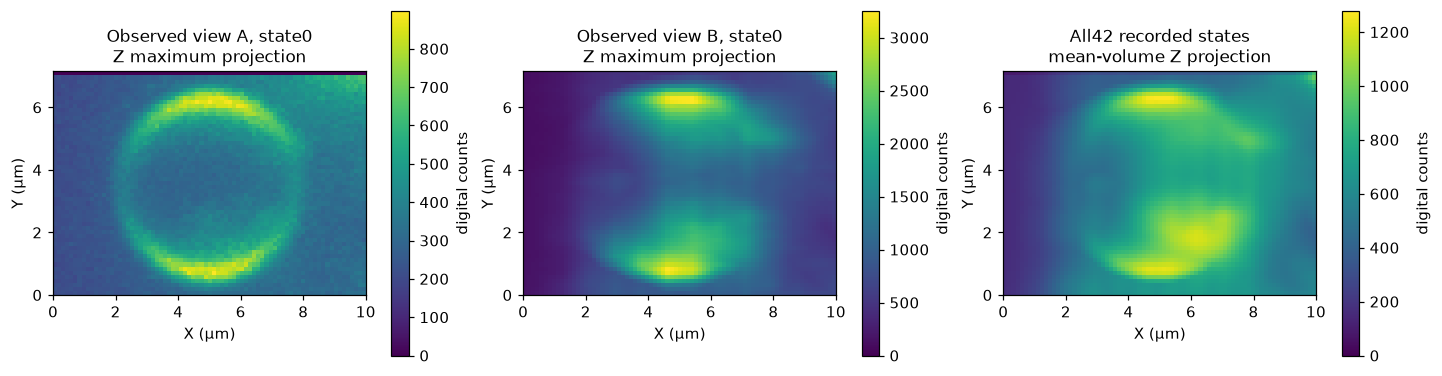

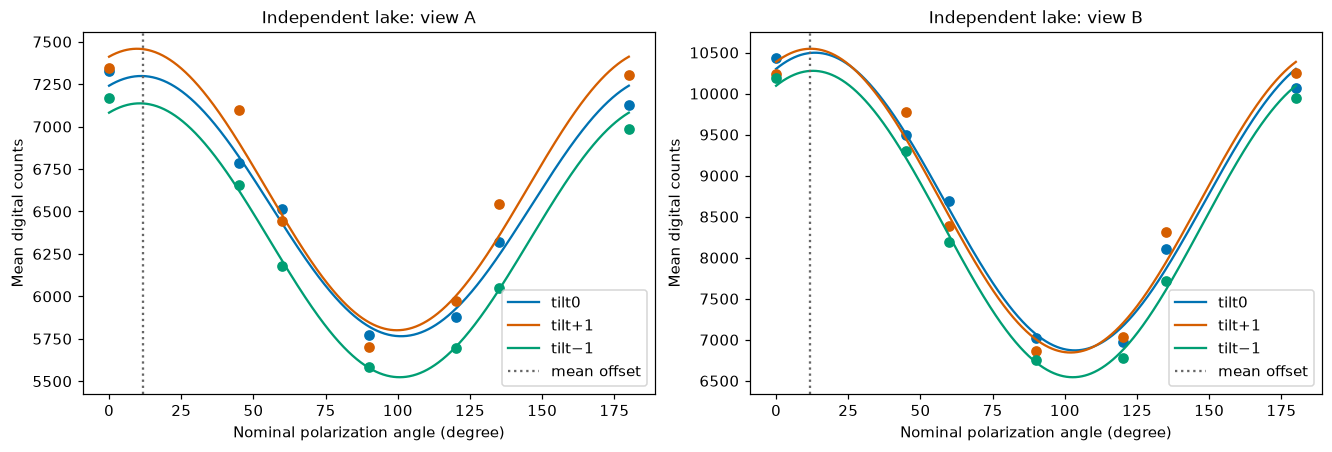

Six fitted maxima (degrees): [11.17117117  9.72972973 10.63063063 13.51351351 12.07207207 12.79279279] mean: 11.651651651651653


In [2]:
obs=raw['observations'][0]
fig,axes=plt.subplots(1,3,figsize=(13,4))
a=obs[...,0,0].max(axis=2);b=obs[...,0,1].max(axis=2);mean=obs.mean(axis=(3,4)).max(axis=2)
image(axes[0],a,'Observed view A, state0\nZ maximum projection',label='digital counts')
image(axes[1],b,'Observed view B, state0\nZ maximum projection',label='digital counts')
image(axes[2],mean,'All42 recorded states\nmean-volume Z projection',label='digital counts')
emit(fig,'figure01_observations',{'view_A':a,'view_B':b,'mean_projection':mean},'Actual real count projections before calibration; all raw states retained.')
prepared=prepare_observations(raw)
fig,axes=plt.subplots(1,2,figsize=(12,4));angles=np.array([0,45,60,90,120,135,180]);grid=np.linspace(0,180,1000)
for v,ax in enumerate(axes):
    for k,color in enumerate(['#0072B2','#D55E00','#009E73']):
        means=prepared['all_calibration_averages'][7*k:7*(k+1),v];abc=prepared['calibration_coefficients'][3*v+k]
        curve=abc[0]+abc[1]*np.cos(2*np.deg2rad(grid))+abc[2]*np.sin(2*np.deg2rad(grid))
        ax.plot(angles,means,'o',color=color);ax.plot(grid,curve,color=color,label=['tilt0','tilt+1','tilt−1'][k])
    ax.axvline(prepared['offset'],color='0.4',ls=':',label='mean offset');ax.set(title=f'Independent lake: view {"AB"[v]}',xlabel='Nominal polarization angle (degree)',ylabel='Mean digital counts');ax.legend()
emit(fig,'figure02_calibration',{'lake_means':prepared['all_calibration_averages'],'abc':prepared['calibration_coefficients'],'offsets':prepared['calibration_offsets']},'Original six cosine fits actively recomputed from independent same-session lake counts.')
print('Six fitted maxima (degrees):',prepared['calibration_offsets'],'mean:',prepared['offset'])

# 3. Physics — dipoles, blur and incomplete angular sensitivity

The illumination response is $3(\mathbf p\cdot\mathbf s)^2/(4\pi)$, where unit vectors $\mathbf p$ and $\mathbf s$ describe polarization and a molecular dipole. Finite-aperture detection is anisotropic in orientation and space. Its radial optical transfer vanishes outside normalized transverse frequency2, while axial response is Gaussian with dimensionless width0.25. Model wavelength561nm, refractive index1.33 and view numerical apertures1.1/.67 follow the selected author analysis.

Expand $f(\mathbf r,\mathbf s)=\sum_j f_j(\mathbf r)Y_j(\mathbf s)$ in15 orthonormal real harmonics through degree4. Their illumination/detection products are evaluated locally by finite surface quadrature. At each spatial frequency the real15-by-measurement matrix $H$ gives $G=H^T F$. Both spatial and angular null directions exist; regularization defines a conditional estimate rather than making those directions measured.

# 4. Method — active calibrated Tikhonov reconstruction

For $H=U\operatorname{diag}(s)V^*$, the source estimator is
$$\widehat F=U\operatorname{diag}\!\left(\frac{s}{s^2+\eta}\right)V^*G.$$
Singular values at or below $10^{-7}$ are suppressed. ALL uses $\eta=0.7$; the two published six-state groups use0.1 and0.7 respectively. This solves the specified regularized linear objective. No positivity projection, extra spatial mask or fitted output scaling is applied.

The original implementation omitted one highest negative spatial-frequency row/column on each odd-sized axis. The qualified source and local method use absolute signed frequency indices, preserving the complete conjugate pairs. The original complex64 Fourier accumulation is retained, followed by the original double-precision inverse FFT convention.

SIX-NO-TILT fresh local runtime 1.442 s; full observation residual 0.2922044990148267


SIX-WITH-TILT fresh local runtime 1.406 s; full observation residual 0.3110702671565399


ALL fresh local runtime 6.576 s; full observation residual 0.28897297000902095


Fresh complete standard path and comparisons: 13.713 s; independent Judge: pass


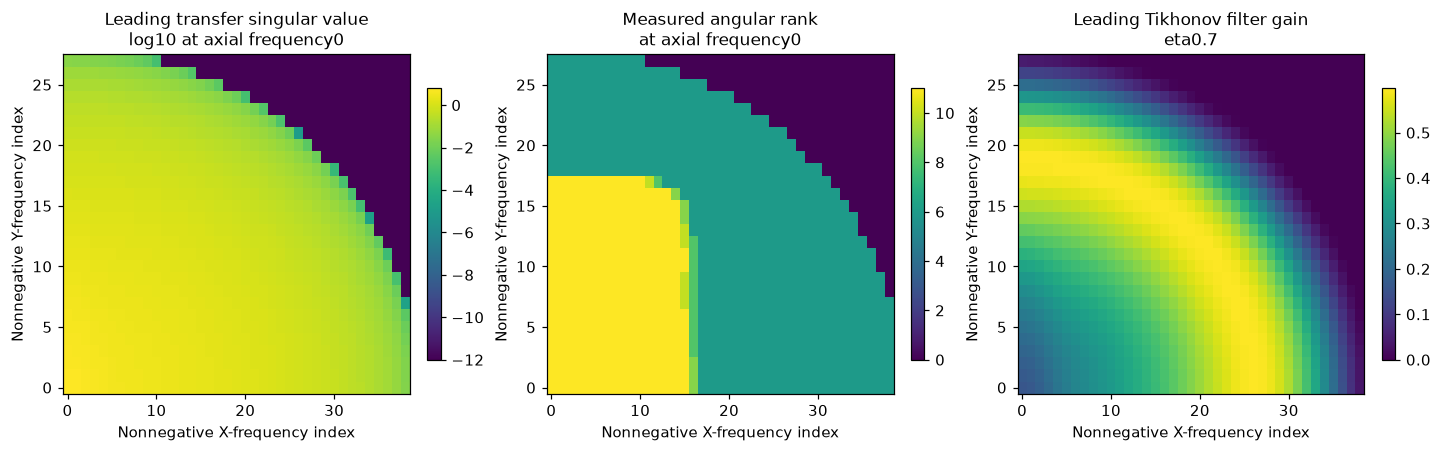

In [3]:
started=time.perf_counter();results={}
for group in ['SIX-NO-TILT','SIX-WITH-TILT','ALL']:
    t=time.perf_counter();results[group]=reconstruct(raw,subset=group)
    print(group,'fresh local runtime',round(time.perf_counter()-t,3),'s; full observation residual',results[group]['relative_forward_residual'])
fresh=results['ALL'];field=fresh['reconstruction'];reference=np.load(ROOT/'evaluation/baseline_reference.npz')['reconstruction'][0]
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=field[None])
spec=importlib.util.spec_from_file_location('independent_evaluator',ROOT/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz');assert report['status']=='pass',report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False))
stage_runtime=time.perf_counter()-started
print('Fresh complete standard path and comparisons:',round(stage_runtime,3),'s; independent Judge:',report['status'])
h=fresh['transfer_fields'];singular=np.linalg.svd(frequency_matrix(h,0,(77,55,80),positive_only=True),compute_uv=False)
rank=(singular>1e-7).sum(axis=-1)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,a,title in zip(axes,[np.log10(np.maximum(singular[...,0],1e-12)),rank,singular[...,0]/(singular[...,0]**2+.7)],['Leading transfer singular value\nlog10 at axial frequency0','Measured angular rank\nat axial frequency0','Leading Tikhonov filter gain\neta0.7']):
    im=ax.imshow(a.T,origin='lower',cmap='viridis',aspect='auto');ax.set(title=title,xlabel='Nonnegative X-frequency index',ylabel='Nonnegative Y-frequency index');fig.colorbar(im,ax=ax,shrink=.8)
emit(fig,'figure03_transfer_singular_system',{'singular_values':singular,'rank':rank},'Actual known OTF singular system; dark transfer regions and reduced angular rank expose the inverse null space.')

# 5. Results — maps, angular distributions and actual comparisons

All results below are fresh local reconstructions unless explicitly labelled as frozen upstream measurements. Molecular density means the angular integral $\sqrt{4\pi}f_0$ in relative instrument units. It is not an absolute concentration. All15 signed coefficient fields are retained, including weak components. The comparisons of published six-state groups also change eta; a separate matched-eta comparison follows.

Generalized fractional anisotropy is $\sqrt{1-f_0^2/\sum_jf_j^2}$, defined as zero for a zero vector. Display peak directors maximize the reconstructed angular distribution over256 fixed nearly uniform directions; they are sampled display summaries, not exact continuous maxima or independent orientation truth. Their antipodal signs are physically equivalent. The source's density-above0.4-of-maximum rule is applied only to3D glyph display, never to reconstruction or scoring.

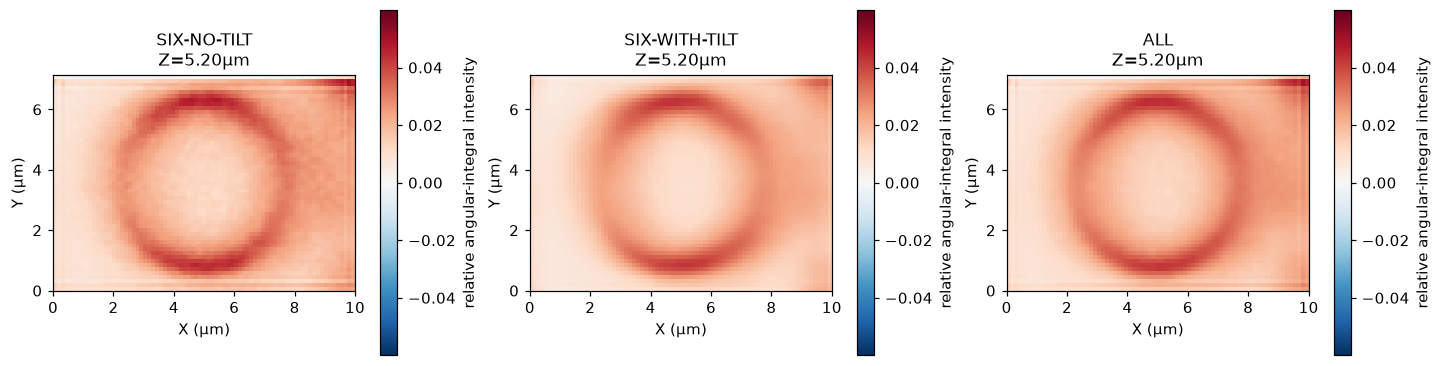

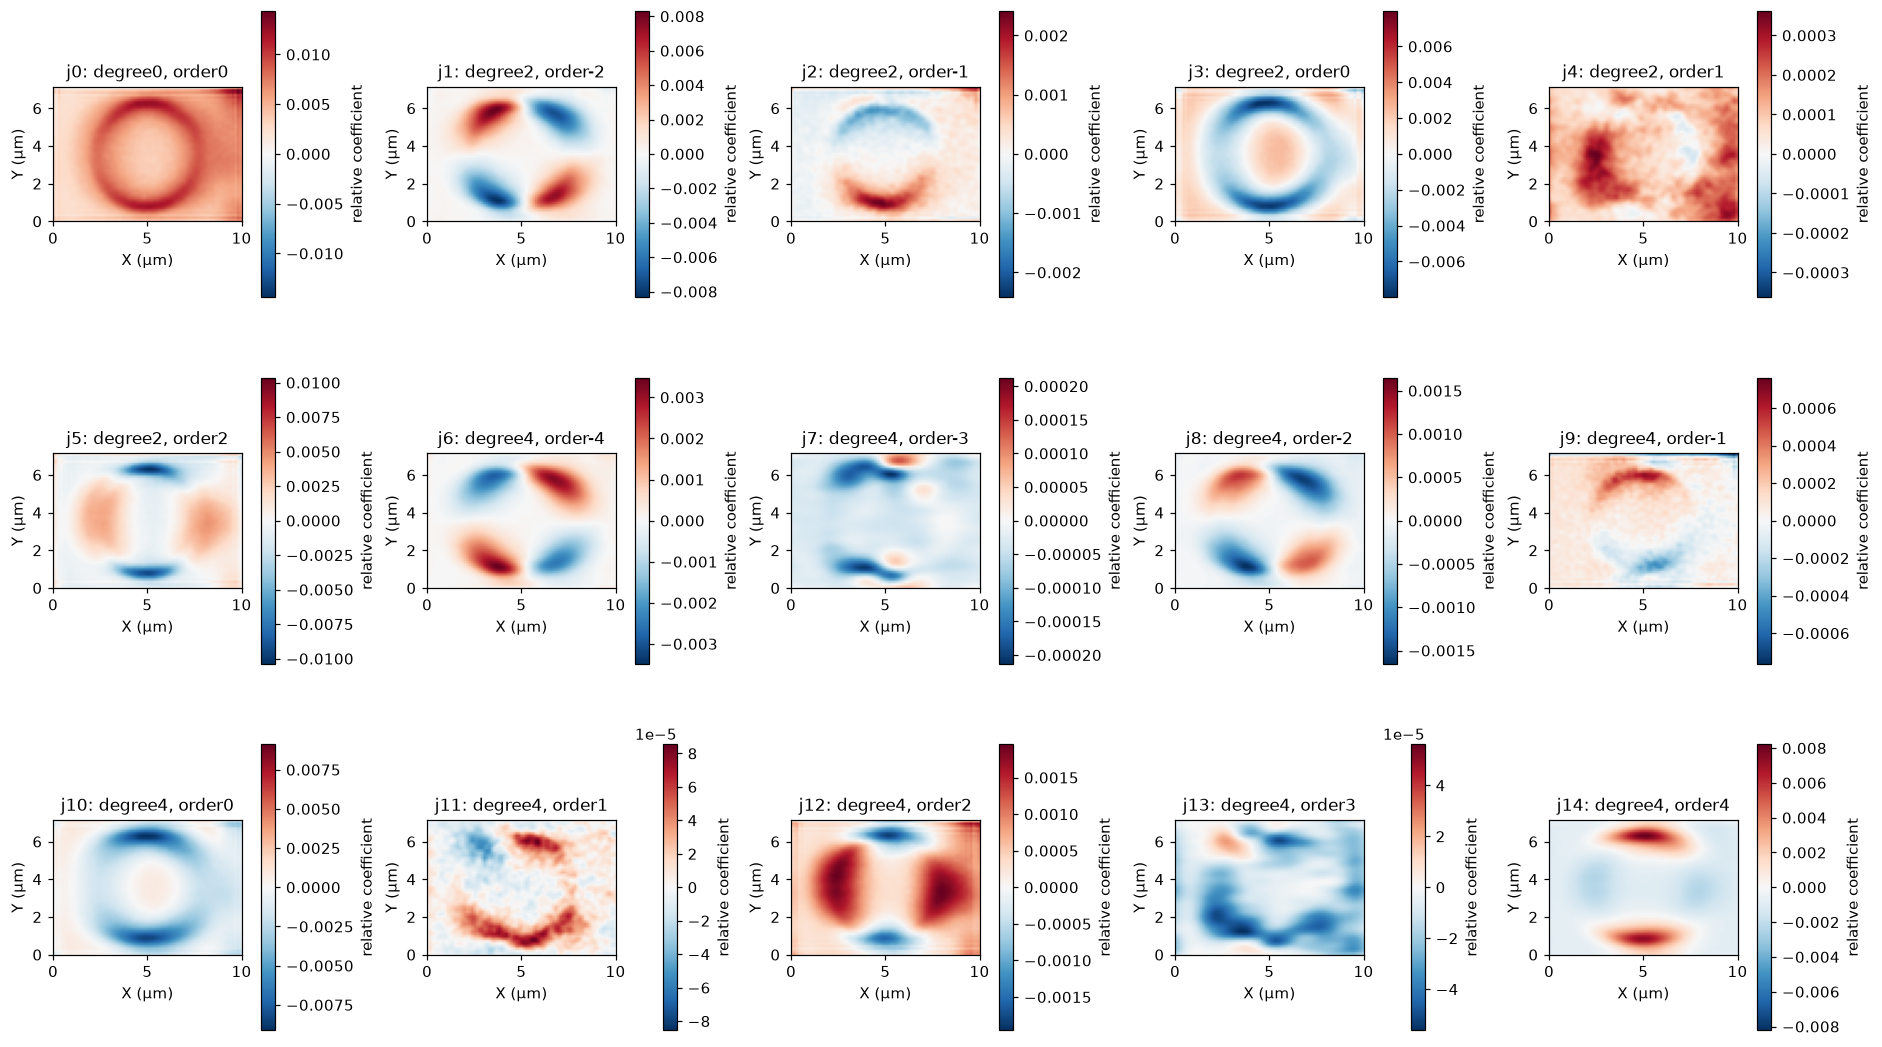

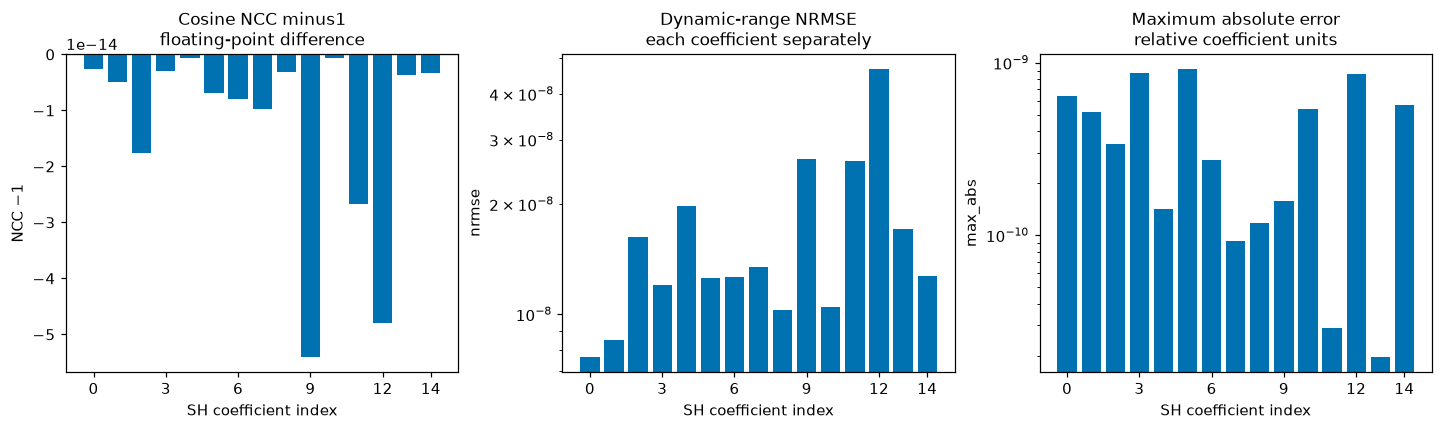

Max per-field DR-NRMSE: 4.681757017624762e-08 maxabs: 9.204353014361302e-10


In [4]:
density={g:np.sqrt(4*np.pi)*r['reconstruction'][...,0] for g,r in results.items()}
fig,axes=plt.subplots(1,3,figsize=(13,4));limit=max(abs(a).max() for a in density.values())
for ax,(g,a) in zip(axes,density.items()):image(ax,a[:,:,40],g+'\nZ=5.20µm',signed=True,limit=limit,label='relative angular-integral intensity')
emit(fig,'figure04_published_groups',{'density_'+g.replace('-','_'):a[:,:,40] for g,a in density.items()},'All three published acquisition groups reconstructed actively, with their original different eta values; not a pure tilt-only ablation.')
fig,axes=plt.subplots(3,5,figsize=(17,10))
for j,ax in enumerate(axes.ravel()):
    image(ax,field[:,:,40,j],f'j{j}: degree{LM[j][0]}, order{LM[j][1]}',signed=True,label='relative coefficient')
emit(fig,'figure05_all15_coefficients',{'coefficient_slice':field[:,:,40,:]},'Every required signed coefficient at the fixed central Z plane, each with symmetric zero-neutral limits.')
metrics=coefficient_metrics(field,reference)
fig,axes=plt.subplots(1,3,figsize=(13,3.8));j=np.arange(15)
for ax,k,title in zip(axes,['ncc','nrmse','max_abs'],['Cosine NCC minus1\nfloating-point difference','Dynamic-range NRMSE\neach coefficient separately','Maximum absolute error\nrelative coefficient units']):
    values=np.array([r[k] for r in metrics]);ax.bar(j,values-1 if k=='ncc' else values,color='#0072B2');ax.set(title=title,xlabel='SH coefficient index',ylabel='NCC −1' if k=='ncc' else k);ax.set_xticks([0,3,6,9,12,14])
    if k!='ncc':ax.set_yscale('log')
    else:ax.ticklabel_format(axis='y',style='sci',scilimits=(0,0),useOffset=False);ax.axhline(0,color='0.5',lw=.8)
emit(fig,'figure06_upstream_parity',{'ncc':np.array([r['ncc'] for r in metrics]),'nrmse':np.array([r['nrmse'] for r in metrics]),'max_abs':np.array([r['max_abs'] for r in metrics])},'Independent frozen qualified-source comparison; numerical agreement is not biological truth.')
print('Max per-field DR-NRMSE:',max(r['nrmse'] for r in metrics),'maxabs:',max(r['max_abs'] for r in metrics))

C:\Users\admin\AppData\Local\Temp\ipykernel_1516\3975465202.py:4: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  fig=plt.figure(figsize=(13,11),layout=None);fig.set_layout_engine(None);fig.subplots_adjust(hspace=.35,wspace=.15);angular_values=[]


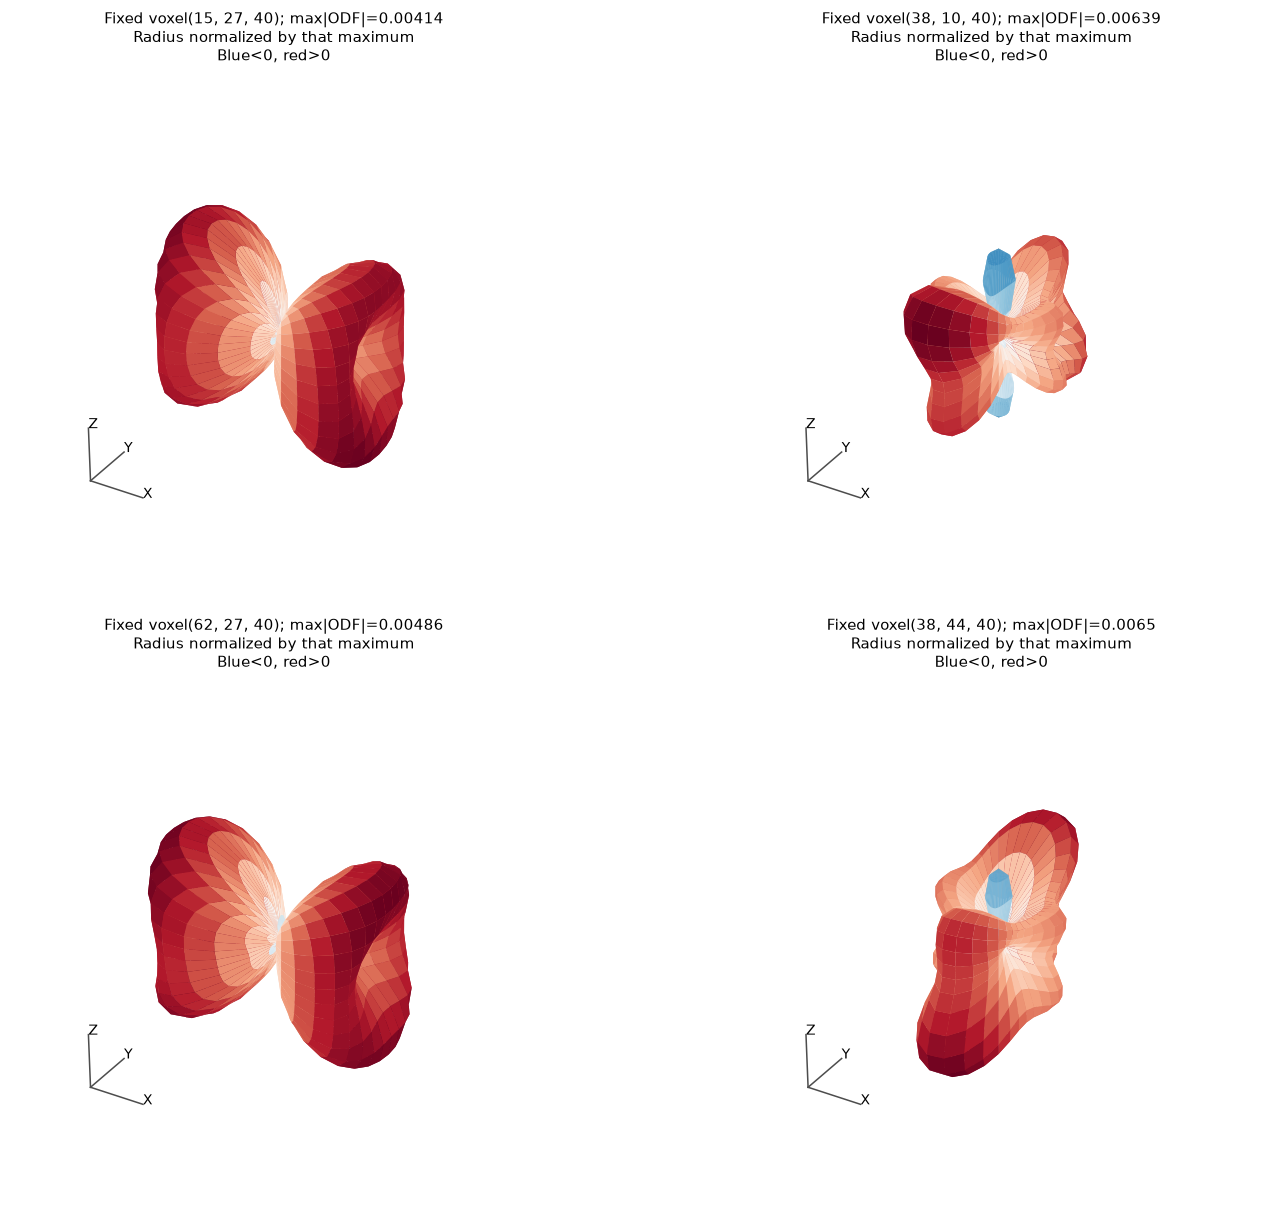

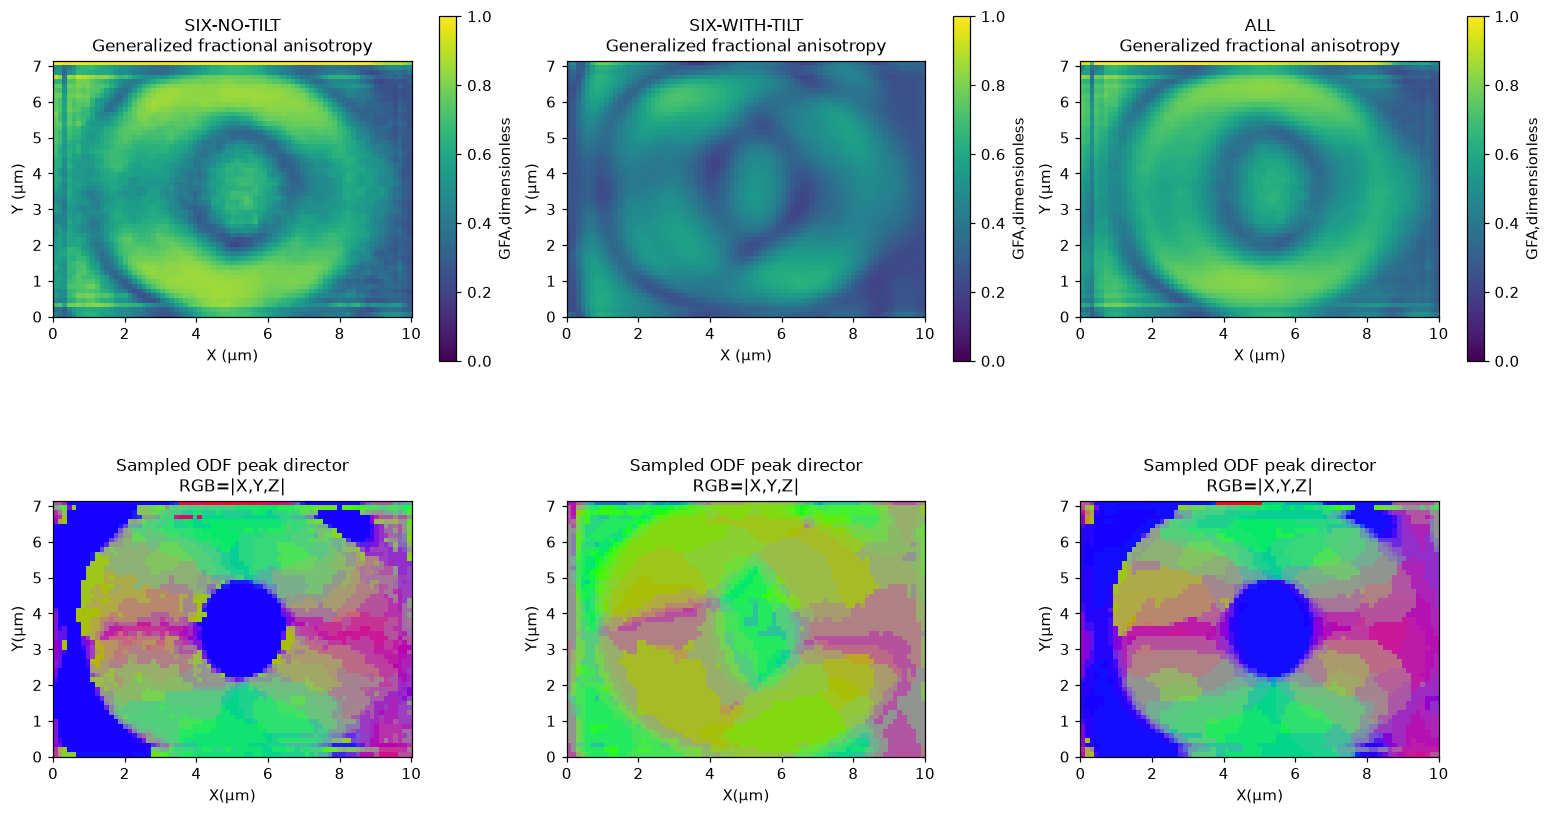

In [5]:
positions=[(15,27,40),(38,10,40),(62,27,40),(38,44,40)]
theta=np.linspace(0,np.pi,25);phi=np.linspace(0,2*np.pi,49);tt,pp=np.meshgrid(theta,phi,indexing='ij');Y=real_harmonics(tt,pp)
unit=np.stack([np.sin(tt)*np.cos(pp),np.sin(tt)*np.sin(pp),np.cos(tt)],axis=-1)
fig=plt.figure(figsize=(13,11),layout=None);fig.set_layout_engine(None);fig.subplots_adjust(hspace=.35,wspace=.15);angular_values=[]
for k,pos in enumerate(positions):
    ax=fig.add_subplot(2,2,k+1,projection='3d');v=Y@field[pos];angular_values.append(v)
    radius=abs(v);scale=max(radius.max(),1e-15);xyz=unit*(radius/scale)[...,None]
    colors=plt.get_cmap('RdBu_r')((v/scale+1)/2)
    ax.plot_surface(xyz[...,0],xyz[...,1],xyz[...,2],facecolors=colors,linewidth=0,antialiased=True,shade=False)
    ax.set(xlim=(-1,1),ylim=(-1,1),zlim=(-1,1));ax.set_axis_off();ax.set_title(f'Fixed voxel{pos}; max|ODF|={scale:.3g}\nRadius normalized by that maximum\nBlue<0, red>0',fontsize=10,pad=12);ax.set_box_aspect((1,1,1))
    base=np.array([-.9,-.9,-.9])
    for axis,label in enumerate('XYZ'):
        tip=base.copy();tip[axis]+=.4;ax.plot([base[0],tip[0]],[base[1],tip[1]],[base[2],tip[2]],color='0.3',lw=1);ax.text(*tip,label,fontsize=9)
emit(fig,'figure07_fixed_voxel_angular_distributions',{'positions':np.array(positions),'theta':theta,'phi':phi,'signed_odfs':np.array(angular_values)},'Actual four fixed-position ODFs; displayed radius is absolute ODF divided by that panel maximum, explicitly labelled with original maximum in relative units; negative values are blue, not clipped.')
diagnostics={g:orientation_diagnostics(r['reconstruction'][:,:,40,:]) for g,r in results.items()}
fig,axes=plt.subplots(2,3,figsize=(14,8))
for col,g in enumerate(results):
    d=diagnostics[g];image(axes[0,col],d['gfa'],g+'\nGeneralized fractional anisotropy',limit=1,label='GFA,dimensionless')
    peak=d['peak_direction'];rgb=abs(peak);axes[1,col].imshow(rgb.transpose(1,0,2),origin='lower',extent=[0,77*.13,0,55*.13]);axes[1,col].set(title='Sampled ODF peak director\nRGB=|X,Y,Z|',xlabel='X(µm)',ylabel='Y(µm)')
emit(fig,'figure08_orientation_and_anisotropy',{'gfa_'+g.replace('-','_'):d['gfa'] for g,d in diagnostics.items()}|{'peak_'+g.replace('-','_'):d['peak_direction'] for g,d in diagnostics.items()},'Computed GFA and sampled peak director on the complete plane; low-density background is retained and should not be interpreted as reliable molecular orientation.')

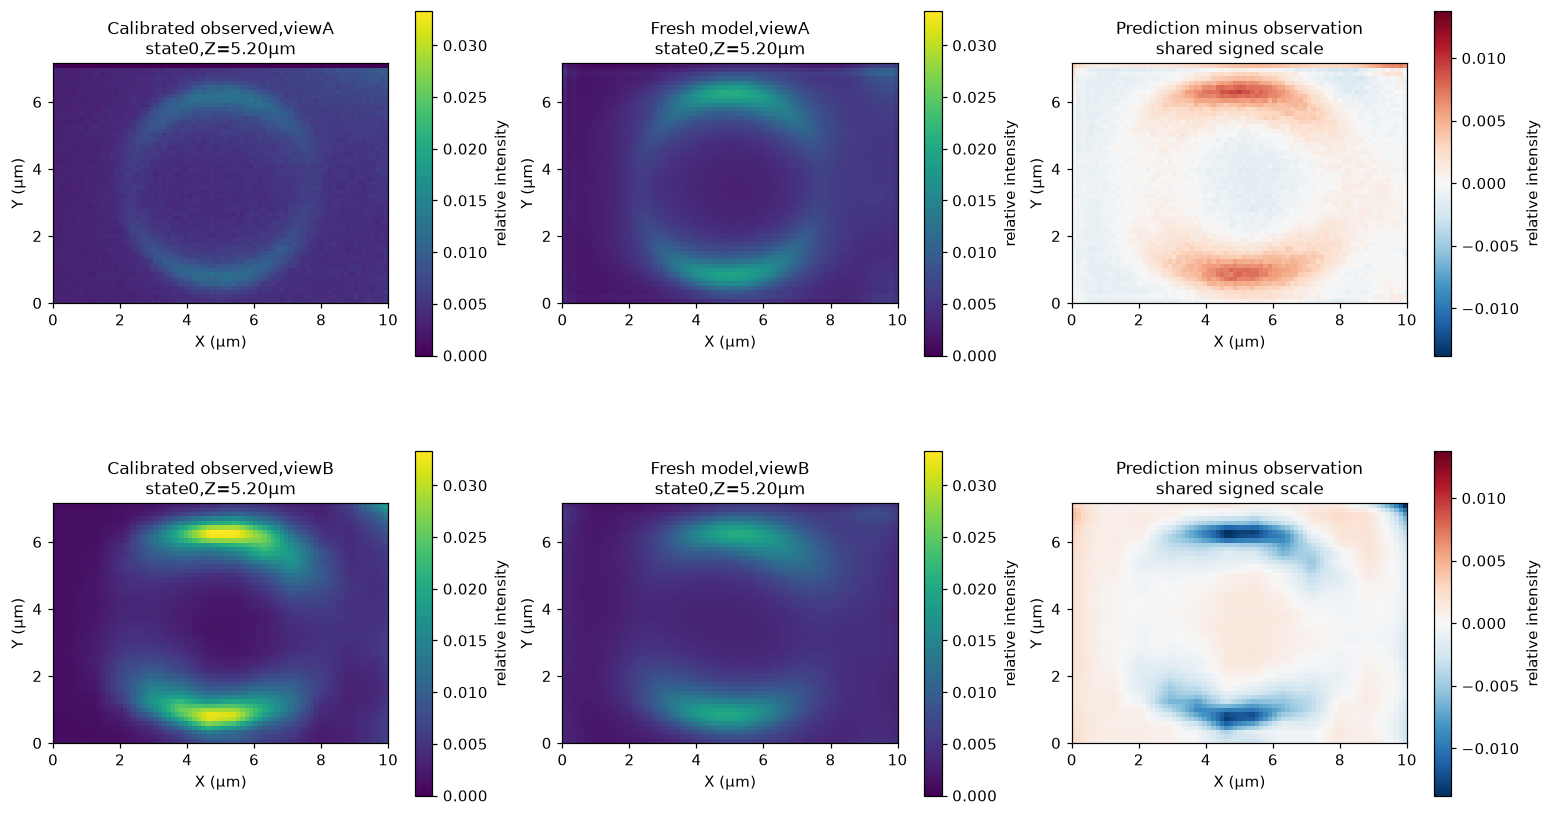

Complete40-state forward relativeL2: 0.28897297000902095 zero model: 1.0


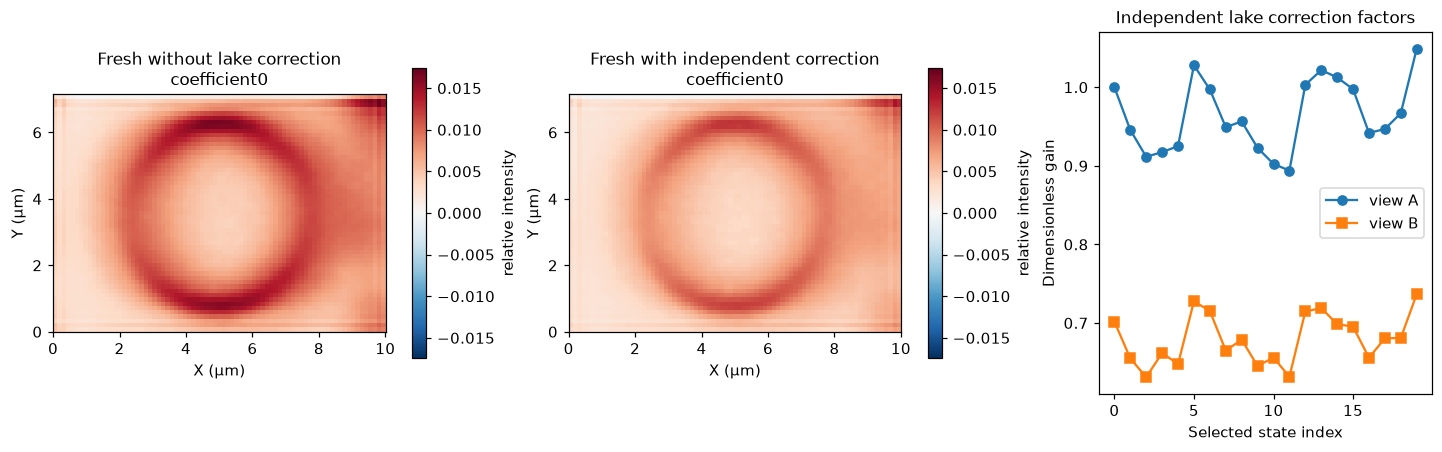

In [6]:
observed=fresh['corrected_observations'];predicted=fresh['prediction'];residual=predicted-observed
fig,axes=plt.subplots(2,3,figsize=(14,8));rlim=max(abs(residual[:,:,40,0,:]).max(),1e-15);plim=max(observed[:,:,40,0,:].max(),predicted[:,:,40,0,:].max())
for v in range(2):
    image(axes[v,0],observed[:,:,40,0,v],f'Calibrated observed,view{"AB"[v]}\nstate0,Z=5.20µm',limit=plim)
    image(axes[v,1],predicted[:,:,40,0,v],f'Fresh model,view{"AB"[v]}\nstate0,Z=5.20µm',limit=plim)
    image(axes[v,2],residual[:,:,40,0,v],'Prediction minus observation\nshared signed scale',signed=True,limit=rlim)
emit(fig,'figure09_observation_consistency',{'observed':observed[:,:,40,0,:],'predicted':predicted[:,:,40,0,:],'residual':residual[:,:,40,0,:],'all_state_relative_residual':np.array(fresh['relative_forward_residual'])},'Actual calibrated data/prediction/residual on a fixed slice, with full40-state volume residual reported separately.')
print('Complete40-state forward relativeL2:',fresh['relative_forward_residual'],'zero model:',1.)
no_cal=reconstruct(raw,calibrate=False)
fig,axes=plt.subplots(1,3,figsize=(13,4));lim=max(abs(field[:,:,40,0]).max(),abs(no_cal['reconstruction'][:,:,40,0]).max())
image(axes[0],no_cal['reconstruction'][:,:,40,0],'Fresh without lake correction\ncoefficient0',signed=True,limit=lim)
image(axes[1],field[:,:,40,0],'Fresh with independent correction\ncoefficient0',signed=True,limit=lim)
factor=fresh['calibration']['calibration_averages'][0,0]*fresh['model_averages']/fresh['calibration']['calibration_averages'].T
axes[2].plot(factor[:,0],'o-',label='view A');axes[2].plot(factor[:,1],'s-',label='view B');axes[2].set(title='Independent lake correction factors',xlabel='Selected state index',ylabel='Dimensionless gain');axes[2].legend()
emit(fig,'figure10_calibration_ablation',{'uncorrected_field0':no_cal['reconstruction'][:,:,40,0],'calibrated_field0':field[:,:,40,0],'correction_factors':factor},'Fresh no-calibration ablation; each measurement condition has its own scale, so maps are compared without claiming independent orientation truth.')
del no_cal

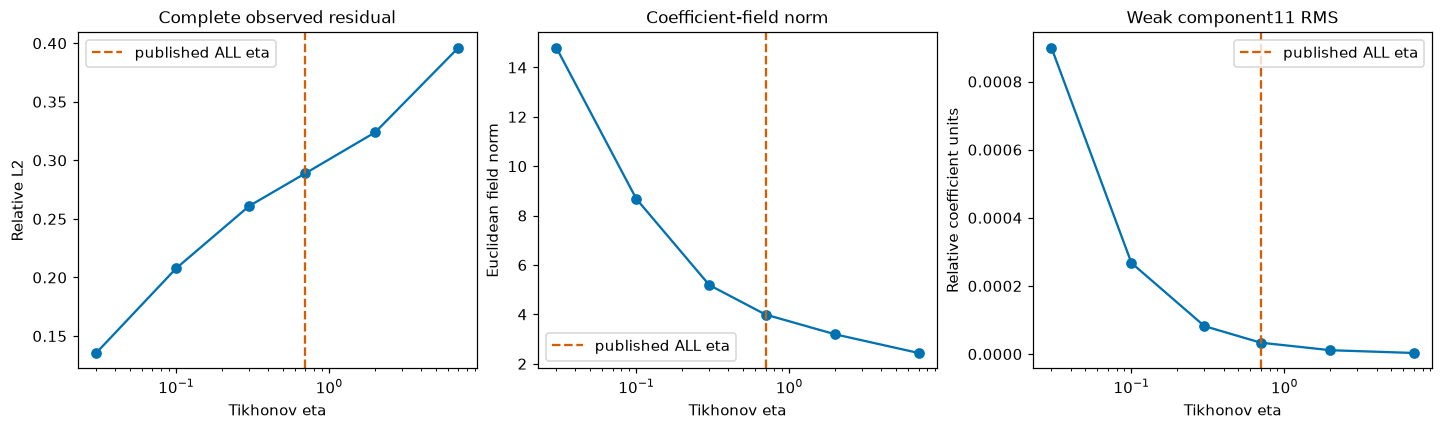

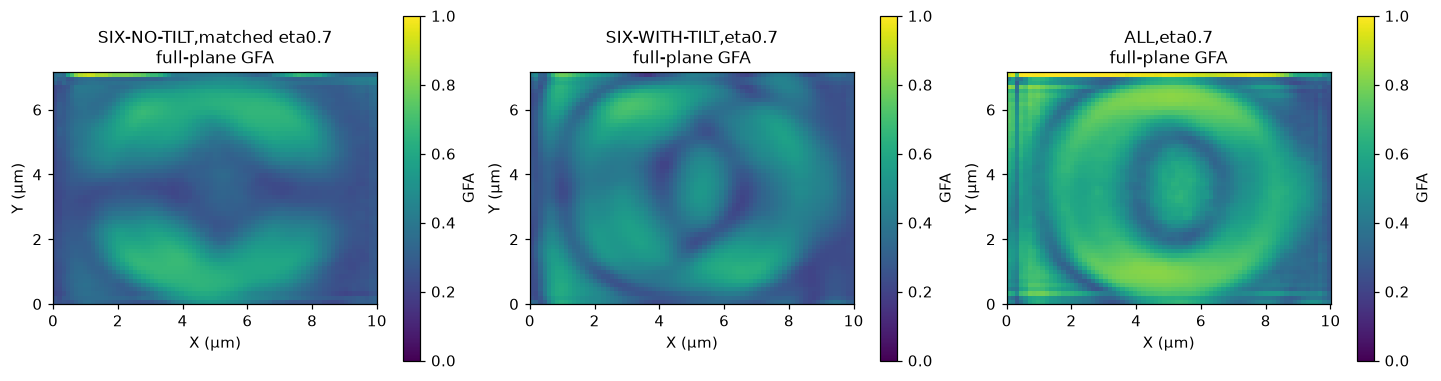

In [7]:
etas=np.array([.03,.1,.3,.7,2.,7.]);sensitivity=[]
for eta in etas:
    f=tikhonov_inverse(observed,h,float(eta));p=forward_linear(f,h)
    sensitivity.append([np.linalg.norm(p-observed)/np.linalg.norm(observed),np.linalg.norm(f),np.sqrt(np.mean(f[...,11]**2))])
sensitivity=np.array(sensitivity)
fig,axes=plt.subplots(1,3,figsize=(13,3.8))
for k,(ax,title,ylabel) in enumerate(zip(axes,['Complete observed residual','Coefficient-field norm','Weak component11 RMS'],['Relative L2','Euclidean field norm','Relative coefficient units'])):
    ax.semilogx(etas,sensitivity[:,k],'o-',color='#0072B2');ax.axvline(.7,color='#D55E00',ls='--',label='published ALL eta');ax.set(title=title,xlabel='Tikhonov eta',ylabel=ylabel);ax.legend()
emit(fig,'figure11_regularization_sensitivity',{'etas':etas,'diagnostics':sensitivity},'Active full-volume inversions at six eta values; published eta is fixed independently of this diagnostic, not selected by cleaner fit.')
matched=tikhonov_inverse(results['SIX-NO-TILT']['corrected_observations'],results['SIX-NO-TILT']['transfer_fields'],.7)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for ax,f,title in zip(axes,[matched,results['SIX-WITH-TILT']['reconstruction'],field],['SIX-NO-TILT,matched eta0.7','SIX-WITH-TILT,eta0.7','ALL,eta0.7']):
    image(ax,orientation_diagnostics(f[:,:,40,:])['gfa'],title+'\nfull-plane GFA',limit=1,label='GFA')
emit(fig,'figure12_matched_regularization',{'matched_no_tilt':matched[:,:,40,:],'with_tilt':results['SIX-WITH-TILT']['reconstruction'][:,:,40,:],'all':field[:,:,40,:]},'Matched eta0.7 comparison supplements rather than replaces the original published parameter settings; changes reflect acquisition support, with no molecular truth claim.')
del matched

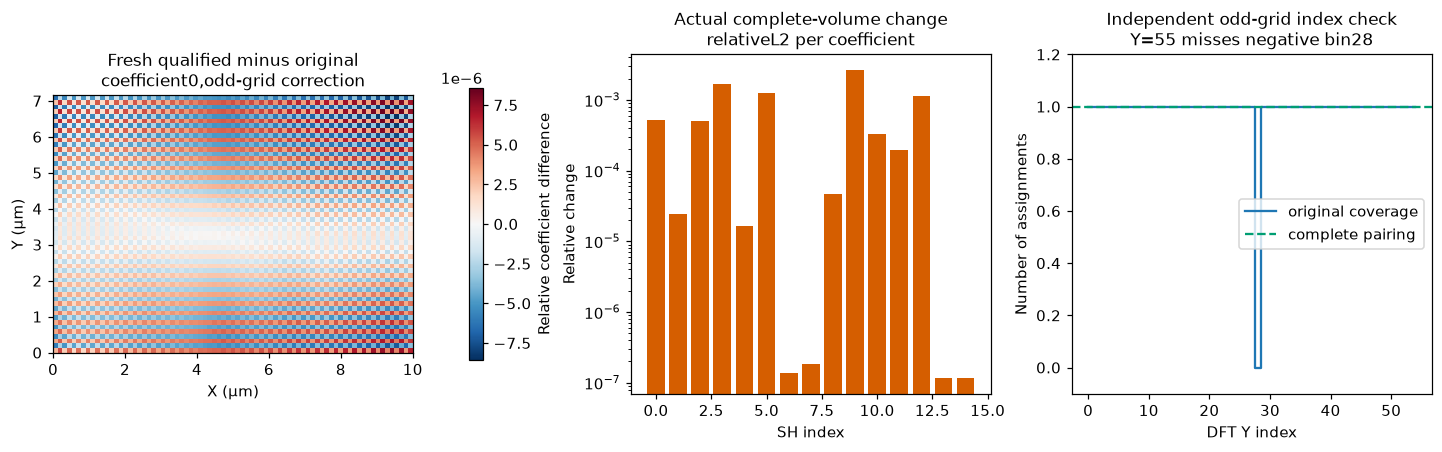

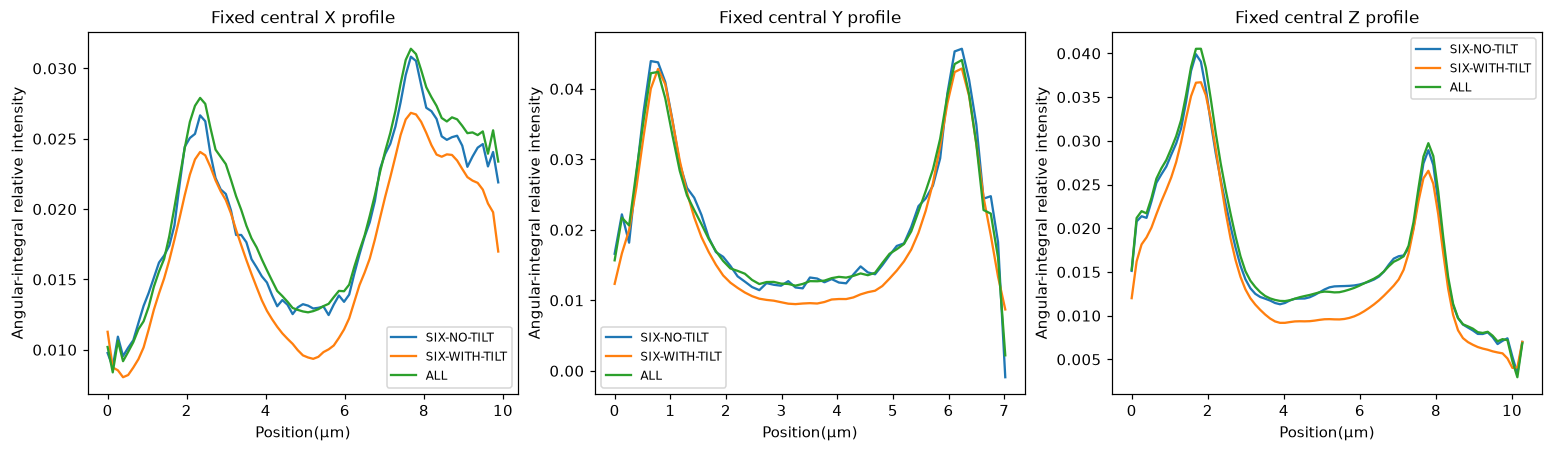

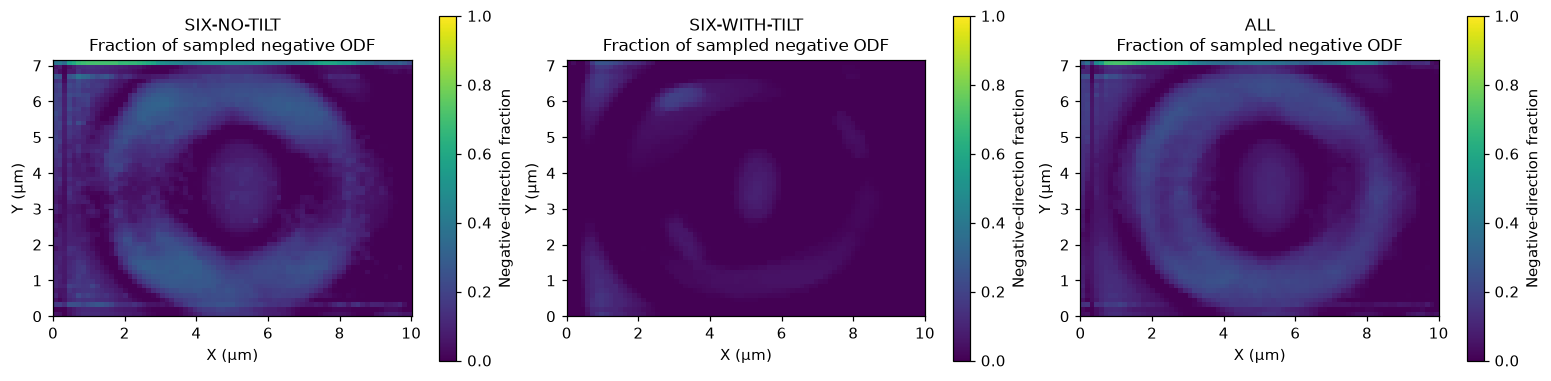

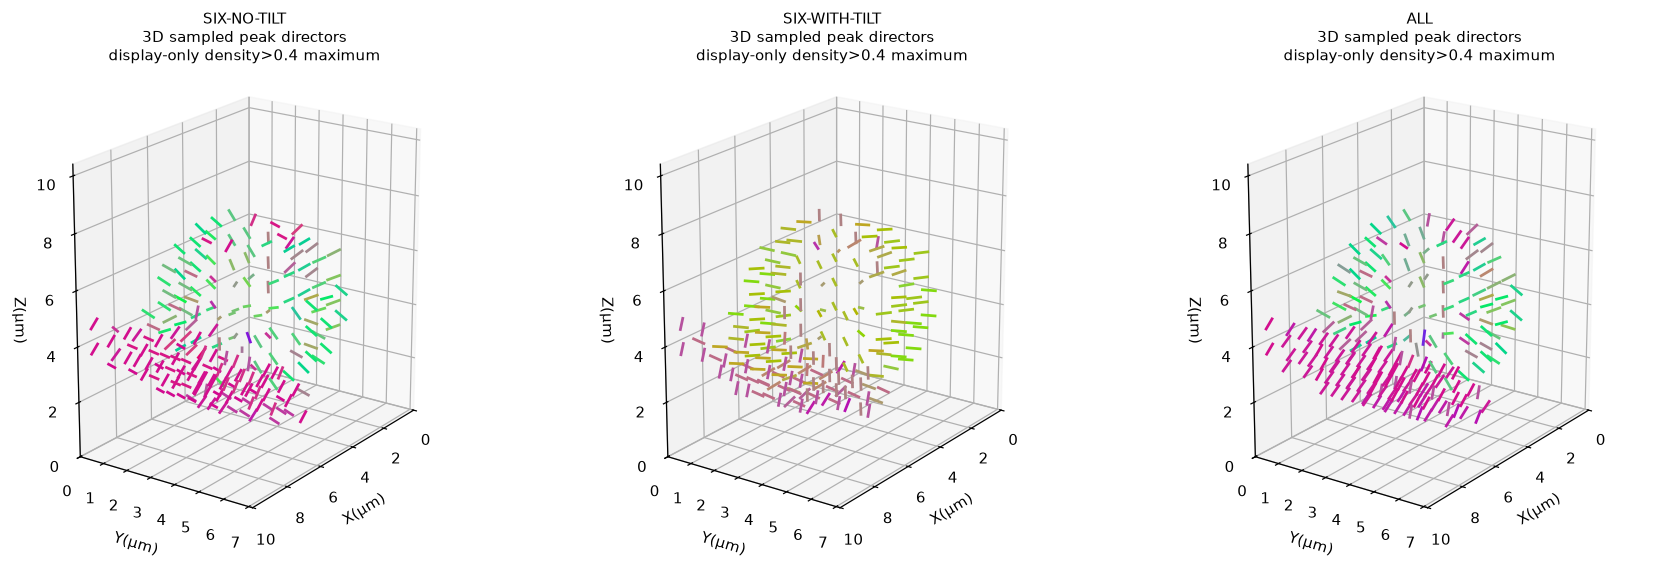

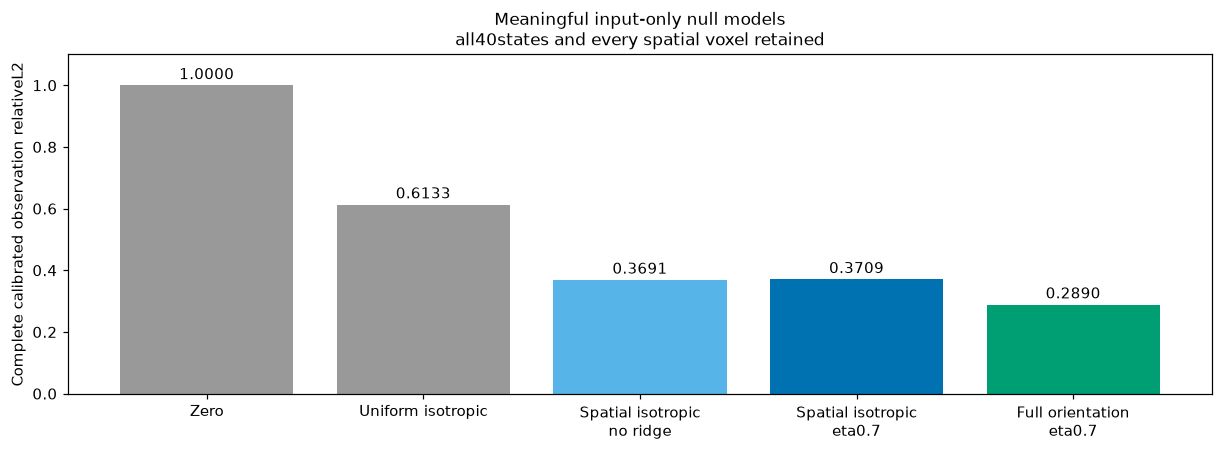

Input-only null residuals: {"zero": 1.0, "uniform_isotropic": 0.6132717572756162, "spatial_isotropic_unregularized": 0.36908134001568027, "spatial_isotropic_regularized": 0.37091902323191217, "uniform_amplitude": 0.004535964781229922}


[
  {
    "group": "SIX-NO-TILT",
    "eta": 0.1,
    "whole_field_relative_L2_vs_qualified_original": 1.3614601343138575e-07,
    "complete_forward_relative_L2": 0.2922044990148267
  },
  {
    "group": "SIX-WITH-TILT",
    "eta": 0.7,
    "whole_field_relative_L2_vs_qualified_original": 7.606297309168693e-08,
    "complete_forward_relative_L2": 0.3110702671565399
  },
  {
    "group": "ALL",
    "eta": 0.7,
    "whole_field_relative_L2_vs_qualified_original": 6.899481727130096e-08,
    "complete_forward_relative_L2": 0.28897297000902095
  }
]
Actual exported figure groups: 17


In [8]:
original=np.load(ROOT/'notebooks/reference_outputs/original_odd_grid_all.npz')['reconstruction'][0]
diff=field-original;relative=np.linalg.norm(diff.reshape(-1,15),axis=0)/np.linalg.norm(reference.reshape(-1,15),axis=0)
fig,axes=plt.subplots(1,3,figsize=(13,4));image(axes[0],diff[:,:,40,0],'Fresh qualified minus original\ncoefficient0,odd-grid correction',signed=True,label='Relative coefficient difference')
axes[1].bar(np.arange(15),relative,color='#D55E00');axes[1].set(title='Actual complete-volume change\nrelativeL2 per coefficient',xlabel='SH index',ylabel='Relative change');axes[1].set_yscale('log')
n=55;coverage=np.zeros(n,int);coverage[:n//2+1]+=1;coverage[slice(None,-(n//2),-1)]+=1
axes[2].step(np.arange(n),coverage,where='mid',label='original coverage');axes[2].axhline(1,color='#009E73',ls='--',label='complete pairing');axes[2].set(title='Independent odd-grid index check\nY=55 misses negative bin28',xlabel='DFT Y index',ylabel='Number of assignments',ylim=(-.1,1.2));axes[2].legend()
emit(fig,'figure13_original_odd_grid_qualification',{'coefficient0_difference':diff[:,:,40,0],'per_coefficient_relative_change':relative,'original_index_coverage':coverage},'Archived unchanged original versus fresh qualified reconstruction and independent frequency-index proof; source failure is retained rather than relabelled unchanged reproduction.')
fig,axes=plt.subplots(1,3,figsize=(14,4));profiles={}
for ax,axis,center in zip(axes,[0,1,2],[(slice(None),27,40),(38,slice(None),40),(38,27,slice(None))]):
    for g,d in density.items():
        profile=d[center];coord=np.arange(len(profile))*.13;ax.plot(coord,profile,label=g);profiles[g.replace('-','_')+'_axis'+str(axis)]=profile
    ax.set(title='Fixed central '+['X','Y','Z'][axis]+' profile',xlabel='Position(µm)',ylabel='Angular-integral relative intensity');ax.legend(fontsize=8)
emit(fig,'figure14_spatial_profiles',profiles,'Actual three orthogonal fixed-position density profiles of all published acquisition groups; no fitted vesicle radius or extrapolated orientation truth.')
fig,axes=plt.subplots(1,3,figsize=(14,4));negative={}
for ax,g in zip(axes,results):
    d=diagnostics[g];image(ax,d['negative_fraction'],g+'\nFraction of sampled negative ODF',limit=1,label='Negative-direction fraction');negative[g.replace('-','_')]=d['negative_fraction']
emit(fig,'figure15_negative_lobes',negative,'Negative angular lobes of the unconstrained linear estimator are quantified over all plane pixels, including background; no output-dependent scoring mask or positivity clipping.')
grid_positions=np.stack(np.meshgrid(np.arange(0,77,7),np.arange(0,55,7),np.arange(0,80,7),indexing='ij'),axis=-1)
fig=plt.figure(figsize=(16,5));glyph_numeric={'positions_voxels':grid_positions}
for column,(group,result) in enumerate(results.items()):
    ax=fig.add_subplot(1,3,column+1,projection='3d');sample=result['reconstruction'][::7,::7,::7];d=orientation_diagnostics(sample)
    keep=sample[...,0]>.4*np.max(result['reconstruction'][...,0]);positions=grid_positions[keep]*.13;directions=d['peak_direction'][keep]
    for pos,direction in zip(positions,directions):
        ends=pos[None,:]+np.array([-.22,.22])[:,None]*direction[None,:]
        ax.plot(ends[:,0],ends[:,1],ends[:,2],color=abs(direction),lw=1.8)
    ax.set(xlim=(0,10.01),ylim=(0,7.15),zlim=(0,10.4),xlabel='X(µm)',ylabel='Y(µm)',zlabel='Z(µm)');ax.set_box_aspect((10.01,7.15,10.4));ax.view_init(elev=20,azim=35);ax.set_title(group+'\n3D sampled peak directors\ndisplay-only density>0.4 maximum',fontsize=10)
    glyph_numeric[group.replace('-','_')+'_peak_directions']=d['peak_direction'];glyph_numeric[group.replace('-','_')+'_display_mask']=keep
emit(fig,'figure16_volume_peak_directors',glyph_numeric,'Full3D acquisition-group orientation comparison on a fixed7-voxel lattice. The original author density0.4-of-max threshold is used for glyph display only; it never changes reconstruction or evaluation support. Director segments are antipodally symmetric, colored RGB=absoluteXYZ components.')
nulls=isotropic_null_residuals(observed,h)
names=['Zero','Uniform isotropic','Spatial isotropic\nno ridge','Spatial isotropic\neta0.7','Full orientation\neta0.7']
values=[nulls['zero'],nulls['uniform_isotropic'],nulls['spatial_isotropic_unregularized'],nulls['spatial_isotropic_regularized'],fresh['relative_forward_residual']]
fig,ax=plt.subplots(figsize=(11,4));ax.bar(np.arange(5),values,color=['0.6','#999999','#56B4E9','#0072B2','#009E73']);ax.set_xticks(np.arange(5),names);ax.set(ylabel='Complete calibrated observation relativeL2',title='Meaningful input-only null models\nall40states and every spatial voxel retained',ylim=(0,1.1))
for k,value in enumerate(values):ax.text(k,value+.02,f'{value:.4f}',ha='center')
emit(fig,'figure17_input_only_null_models',{'relative_L2':np.asarray(values),'uniform_amplitude':np.array(nulls['uniform_amplitude'])},'Active complete-domain comparison against zero, best one-scalar uniform isotropic, and spatially varying isotropic models with/without matched ridge. No reference-derived nulls, masks or clipping; the no-ridge model has weaker regularization explicitly.')
print('Input-only null residuals:',json.dumps(nulls))
summary=[]
for group,result in results.items():
    upstream=reference if group=='ALL' else np.load(ROOT/'notebooks/reference_outputs'/(group.lower()+'.npz'))['reconstruction'][0]
    summary.append({'group':group,'eta':result['eta'],'whole_field_relative_L2_vs_qualified_original':float(np.linalg.norm(result['reconstruction']-upstream)/np.linalg.norm(upstream)),'complete_forward_relative_L2':result['relative_forward_residual']})
print(json.dumps(summary,indent=2))
(FIGURE_DIR/'figure_index.json').write_text(json.dumps({'figures':figures,'actual_group_metrics':summary,'standard_metrics':metrics,'execution_standard_comparisons_seconds':stage_runtime},indent=2,allow_nan=False))
print('Actual exported figure groups:',len(figures))

# 6. Conclusion — validated method agreement with explicit physical limits

The notebook actively reconstructed all three published acquisition groups on the exact real author ROI, saved the fresh ALL result, and passed the independent evaluator. Its all15 coefficient comparisons test faithful method extraction; the full observed residual measures how well the conditional optical model explains the data. Neither is a measurement of true molecular orientation error.

The actual calibration and regularization comparisons show how instrument response and incomplete angular information affect the inferred distribution. Matched-eta and original-parameter comparisons are both retained. The independent odd-grid check explains and quantifies the minimal source qualification. Signed coefficients, negative angular lobes and noisy low-density orientation estimates remain visible. GFA and peak directions in weak-signal regions are especially uncertain, and the truncated harmonic expansion/regularizer cannot supply missing angular information. Absolute concentration, external biological truth and a complete reproduction of other specimens in the paper are not claimed.

Every figure is paired with its computed numerical arrays and PNG/SVG/PDF exports in the private figure archive. Cached upstream references are labelled as such; they never replace the fresh reconstruction path.